## Pregunta 2 — Deconvolución de Wiener y Tikhonov iterativo

### Importaciones

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import p2_implementacion as p2

# Configuración de visualización
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["font.size"] = 11


In [2]:
import importlib
importlib.reload(p2)

<module 'p2_implementacion' from 'c:\\Users\\apfib\\OneDrive\\Desktop\\IEE2714\\t3-IEE2714\\p2_implementacion.py'>

## Carga y visualizacion de archivos

In [3]:
# Cargar imagen y PSF
ruta_imagen = os.path.join("tarea3_files", "cameraman.jpg")
ruta_psf = os.path.join("tarea3_files", "psf.png")

img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
psf_original = cv2.imread(ruta_psf, cv2.IMREAD_GRAYSCALE)

img = img.astype(np.float64) / 255.0
psf_original = psf_original.astype(np.float64)

print("Dimensiones imagen:", img.shape)
print("Dimensiones PSF original:", psf_original.shape)
print("Rango imagen:", img.min(), img.max())
print("Suma PSF original:", psf_original.sum())

Dimensiones imagen: (256, 256)
Dimensiones PSF original: (15, 15)
Rango imagen: 0.0 1.0
Suma PSF original: 9041.0


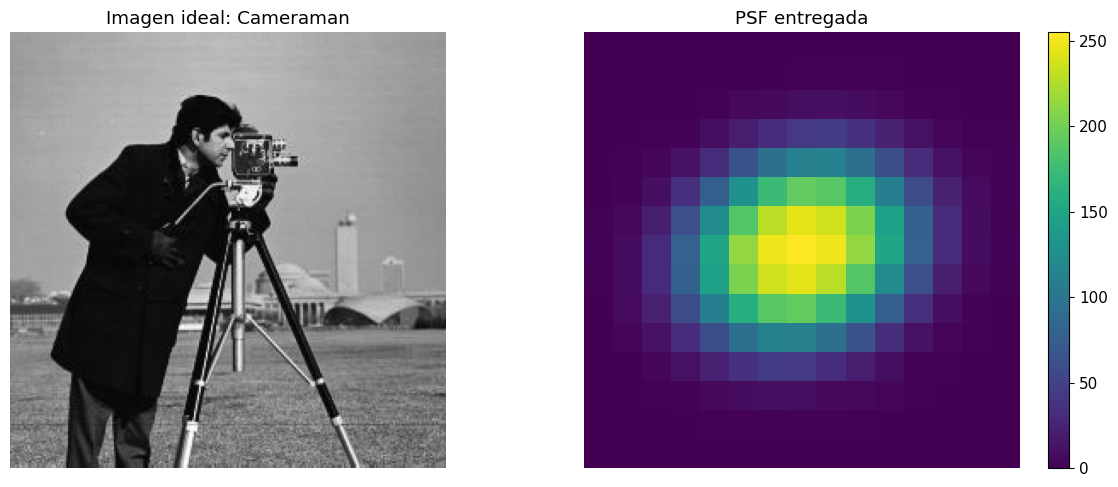

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Imagen ideal: Cameraman")
axes[0].axis("off")

im = axes[1].imshow(psf_original, cmap="viridis")
axes[1].set_title("PSF entregada")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## Simulación de ruido


Suma PSF preparada: 1.0
Dimensiones PSF preparada: (256, 256)
Magnitud máxima de H: 1.0


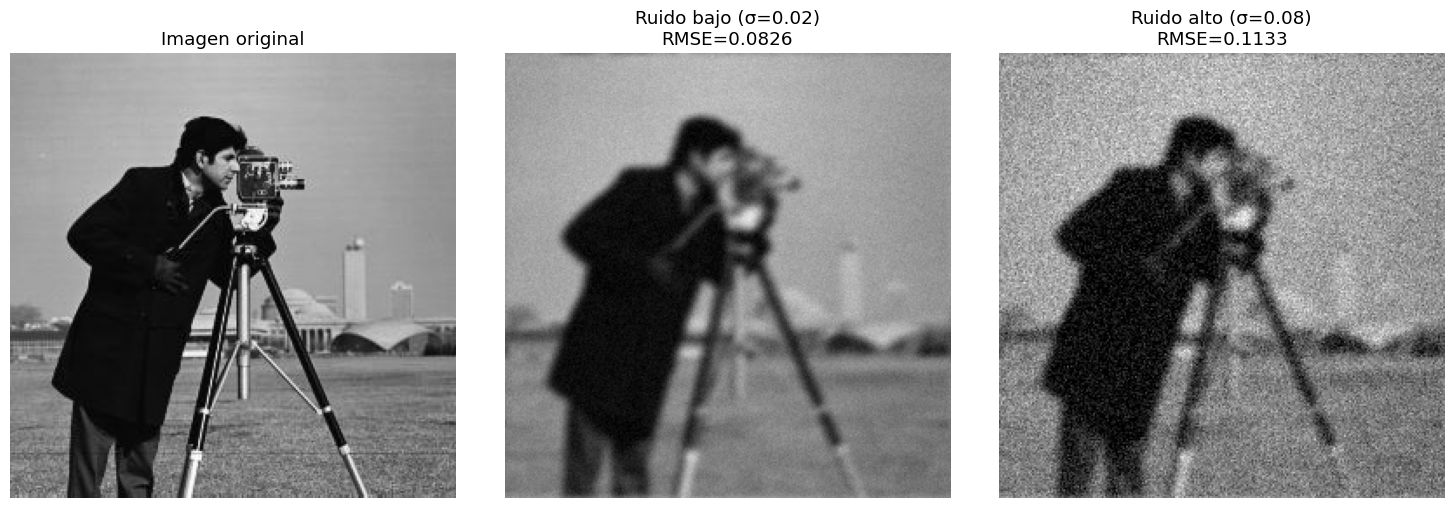

RMSE degradación con ruido bajo: 0.08256000414494984
RMSE degradación con ruido alto: 0.11332983230590532


In [5]:
# Preparar PSF y obtener H
psf_preparada, H = p2.preparar_psf(
    psf_original.copy(), img.shape
)

print("\nSuma PSF preparada:", psf_preparada.sum())
print("Dimensiones PSF preparada:", psf_preparada.shape)
print("Magnitud máxima de H:", np.abs(H).max())

# Simular degradación con dos niveles de ruido
sigma_bajo = 0.02
sigma_alto = 0.08

y_bajo = p2.simular_degradacion(
    img, H, sigma_ruido=sigma_bajo, seed=42
)

y_alto = p2.simular_degradacion(
    img, H, sigma_ruido=sigma_alto, seed=42
)

# Calcular RMSE
rmse_degradado_bajo = p2.calcular_rmse(img, y_bajo)
rmse_degradado_alto = p2.calcular_rmse(img, y_alto)

# Visualizar
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Imagen original")

axes[1].imshow(y_bajo, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(
    f"Ruido bajo (σ={sigma_bajo})\nRMSE={rmse_degradado_bajo:.4f}"
)

axes[2].imshow(y_alto, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(
    f"Ruido alto (σ={sigma_alto})\nRMSE={rmse_degradado_alto:.4f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("RMSE degradación con ruido bajo:", rmse_degradado_bajo)
print("RMSE degradación con ruido alto:", rmse_degradado_alto)


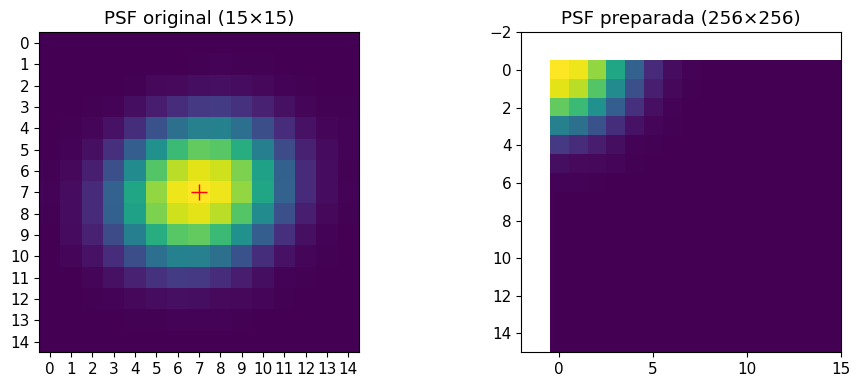

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(psf_original, cmap="viridis")
axes[0].set_title("PSF original (15×15)")
axes[0].plot(7, 7, "r+", markersize=12)
axes[0].set_xticks(range(15))
axes[0].set_yticks(range(15))

axes[1].imshow(psf_preparada, cmap="viridis")
axes[1].set_title("PSF preparada (256×256)")
axes[1].set_xlim(-2, 15)
axes[1].set_ylim(15, -2)

plt.tight_layout()
plt.show()

## 1. Para Wiener, explore K en una escala suficientemente amplia, preferentemente logarítmica. Para al menos dos niveles de ruido, grafique RMSE versus K, determine el valor óptimo y compare las reconstrucciones correspondientes. 

In [7]:
# Rango logarítmico de K
valores_K = np.logspace(-6, -1, 81)

# Niveles de ruido y sus imágenes degradadas
niveles_ruido = {
    "Ruido bajo": (sigma_bajo, y_bajo),
    "Ruido alto": (sigma_alto, y_alto)
}
resultados_wiener = {}

# Restaurar para cada K y calcular RMSE
for nombre, (sigma, y) in niveles_ruido.items():
    rmse_valores = []
    restauraciones = []

    for K in valores_K:
        # Restauración Wiener
        x_hat = p2.deconvolucion_wiener(y, H, K)
        # Evaluación respecto de la imagen original
        rmse = p2.calcular_rmse(img, x_hat)
        rmse_valores.append(rmse)
        restauraciones.append(x_hat)

    rmse_valores = np.array(rmse_valores)

    # Encontrar K que minimiza el RMSE
    idx_optimo = np.argmin(rmse_valores)

    K_optimo = valores_K[idx_optimo]
    rmse_optimo = rmse_valores[idx_optimo]
    x_optima = restauraciones[idx_optimo]

    resultados_wiener[nombre] = {
        "sigma": sigma,
        "rmse": rmse_valores,
        "K_optimo": K_optimo,
        "rmse_optimo": rmse_optimo,
        "imagen_optima": x_optima
    }

    print(f"\n{nombre} (sigma = {sigma})")
    print(f"K óptimo: {K_optimo:.6e}")
    print(f"RMSE mínimo: {rmse_optimo:.6f}")


Ruido bajo (sigma = 0.02)
K óptimo: 1.154782e-02
RMSE mínimo: 0.069509

Ruido alto (sigma = 0.08)
K óptimo: 4.869675e-02
RMSE mínimo: 0.085212


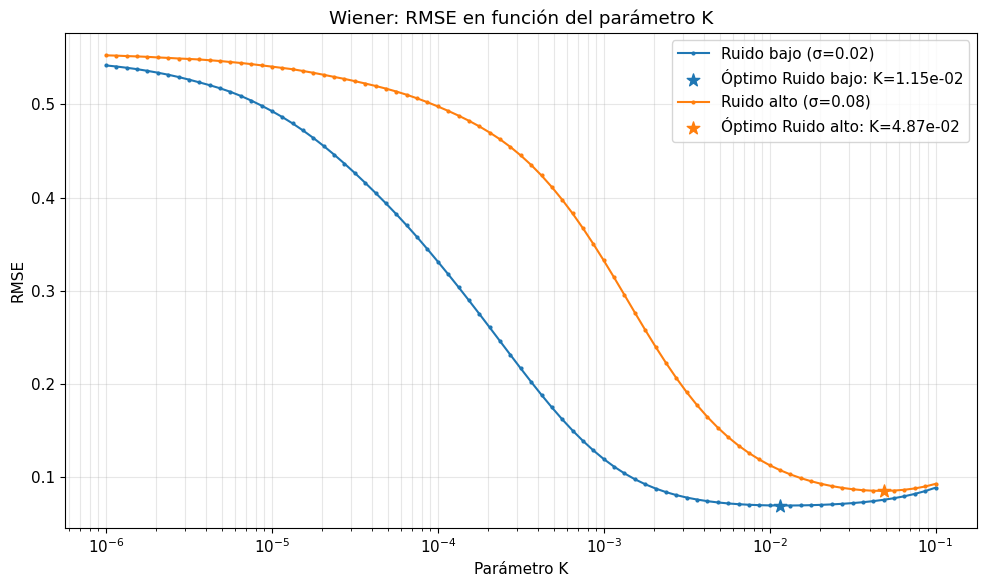

In [8]:
# Graficar RMSE versus K
fig, ax = plt.subplots(figsize=(10, 6))
for nombre, resultado in resultados_wiener.items():
    ax.plot(
        valores_K,
        resultado["rmse"],
        marker=".",
        markersize=4,
        label=f'{nombre} (σ={resultado["sigma"]})'
    )

    # Marcar el mínimo de cada curva
    ax.scatter(
        resultado["K_optimo"],
        resultado["rmse_optimo"],
        s=90,
        marker="*",
        zorder=5,
        label=f'Óptimo {nombre}: K={resultado["K_optimo"]:.2e}'
    )

ax.set_xscale("log")
ax.set_xlabel("Parámetro K")
ax.set_ylabel("RMSE")
ax.set_title("Wiener: RMSE en función del parámetro K")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

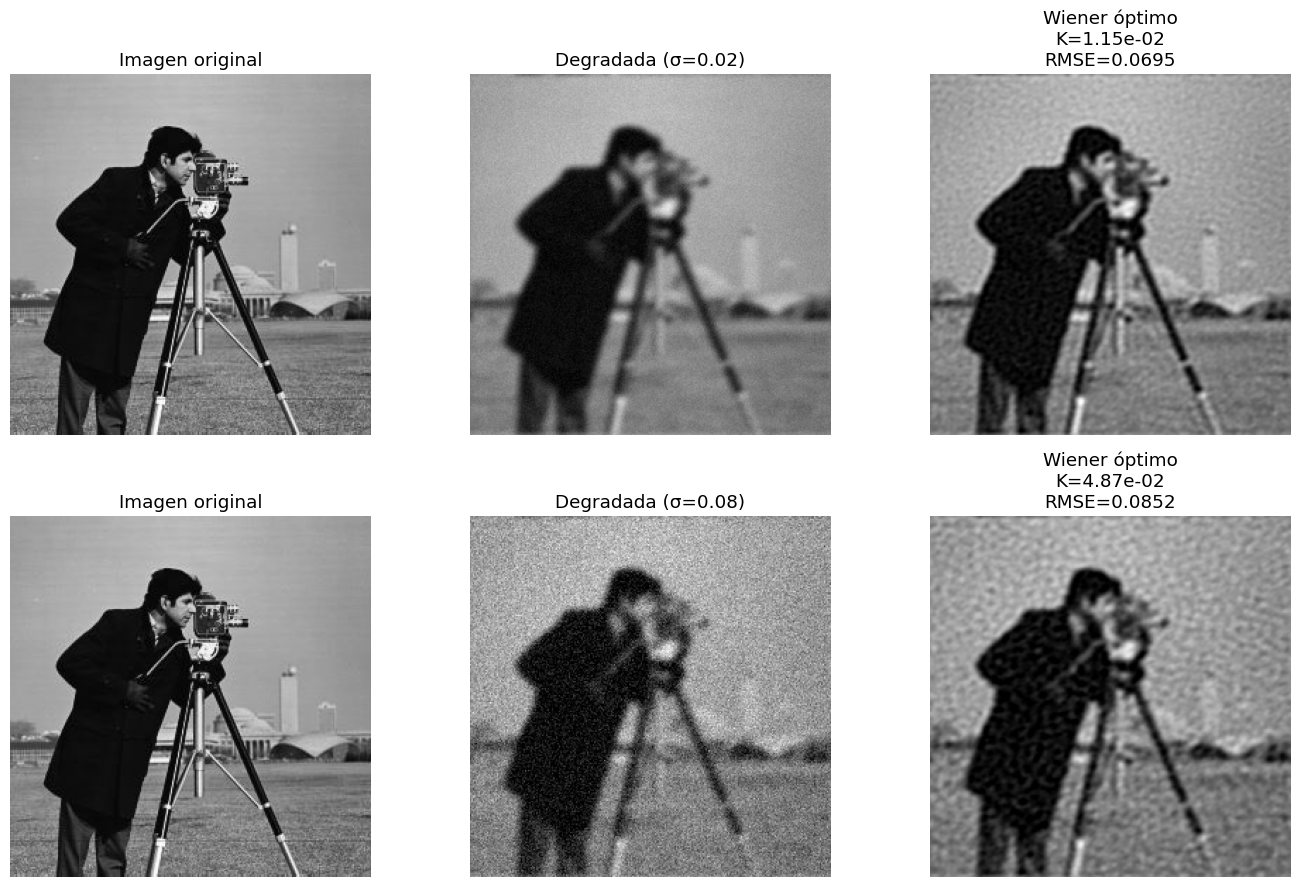

In [9]:
# Comparación de las reconstrucciones óptimas
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

# Primera fila: ruido σ=0.02
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Imagen original")

axes[0, 1].imshow(y_bajo, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title(f"Degradada (σ={sigma_bajo})")

axes[0, 2].imshow(
    resultados_wiener["Ruido bajo"]["imagen_optima"],
    cmap="gray", vmin=0, vmax=1
)
axes[0, 2].set_title(
    f'Wiener óptimo\nK={resultados_wiener["Ruido bajo"]["K_optimo"]:.2e}'
    f'\nRMSE={resultados_wiener["Ruido bajo"]["rmse_optimo"]:.4f}'
)

# Segunda fila: ruido σ=0.08
axes[1, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Imagen original")

axes[1, 1].imshow(y_alto, cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title(f"Degradada (σ={sigma_alto})")

axes[1, 2].imshow(
    resultados_wiener["Ruido alto"]["imagen_optima"],
    cmap="gray", vmin=0, vmax=1
)
axes[1, 2].set_title(
    f'Wiener óptimo\nK={resultados_wiener["Ruido alto"]["K_optimo"]:.2e}'
    f'\nRMSE={resultados_wiener["Ruido alto"]["rmse_optimo"]:.4f}'
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


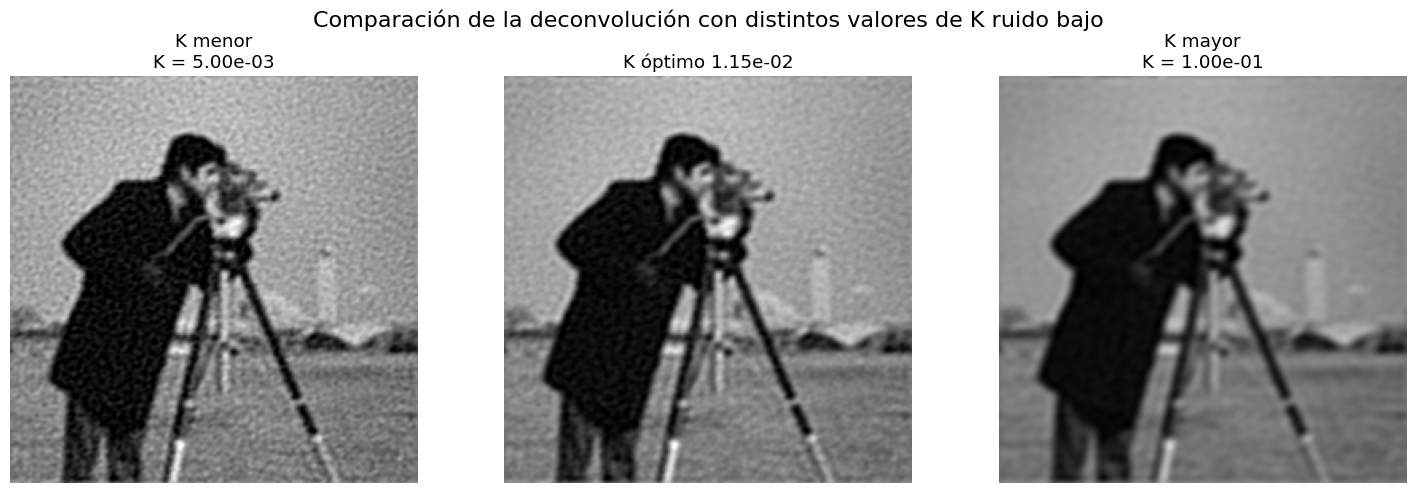

In [10]:
# Valores de K seleccionados
K_menor = 0.005
K_mayor = 0.1

# Aplicar ambos valores sobre la misma imagen degradada
imagen_K_menor = p2.deconvolucion_wiener(y_bajo, H, K_menor)
imagen_K_mayor = p2.deconvolucion_wiener(y_bajo, H, K_mayor)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[1].imshow(resultados_wiener["Ruido bajo"]["imagen_optima"], cmap="gray", vmin=0, vmax=1)
axes[1].set_title(F"K óptimo {resultados_wiener['Ruido bajo']['K_optimo']:.2e}")
axes[1].axis("off")

axes[0].imshow(imagen_K_menor, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"K menor\nK = {K_menor:.2e}")
axes[0].axis("off")

axes[2].imshow(imagen_K_mayor, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"K mayor\nK = {K_mayor:.2e}")
axes[2].axis("off")

plt.suptitle(
    "Comparación de la deconvolución con distintos valores de K ruido bajo",
    fontsize=16
)
plt.tight_layout()
plt.show()

Se evaluó el comportamiento del filtro de Wiener para dos niveles de ruido gaussiano, con desviaciones estándar $\sigma=0.02$ y $\sigma=0.08$. Para cada caso, se exploraron 81 valores del parámetro de regularización K distribuidos logarítmicamente entre $10^{-6}$ y $10^{-1}$.

Para cada valor de K se realizó la restauración de la imagen degradada y se calculó el RMSE respecto de la imagen original, seleccionando como óptimo aquel valor que minimiza esta métrica.

Los resultados muestran que, para el nivel de ruido bajo, el valor óptimo corresponde a K=0.01155, obteniéndose un RMSE mínimo de 0.06951. Para el nivel de ruido alto, el valor óptimo aumenta a K=0.04870, con un RMSE mínimo de 0.08521.

Se observa que, para valores pequeños de K, el RMSE es elevado debido a la amplificación del ruido en las frecuencias donde la respuesta de la PSF es reducida. A medida que aumenta K, esta amplificación disminuye y mejora la calidad de la reconstrucción, hasta alcanzar un mínimo. Sin embargo, al continuar aumentando la regularización, el RMSE vuelve a crecer debido a la pérdida de información de alta frecuencia y al suavizado excesivo de la imagen.

Finalmente, se observa que el nivel de ruido alto requiere un valor de K óptimo mayor que el nivel de ruido bajo. Esto es consistente con el comportamiento esperado del filtro de Wiener, ya que una mayor presencia de ruido requiere una regularización más intensa para evitar su amplificación durante la restauración.

## 2. Para uno de los niveles de ruido, repita la reconstrucción de Wiener usando una PSF ligeramente incorrecta. Defina la perturbación realizada y analice su efecto mediante la imagen reconstruida, el RMSE y al menos un recorte ampliado. 

Nivel de ruido: sigma = 0.02
K utilizado: 0.011548
Perturbación PSF: Desfase del centro en 2 píxeles (np.roll)

--- Resultados ---
RMSE PSF correcta:   0.069509
RMSE PSF incorrecta: 0.115412
Incremento RMSE:     66.04 %


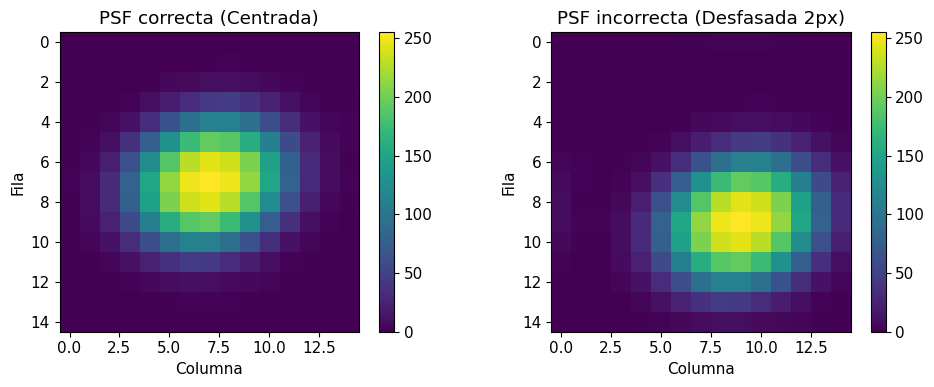

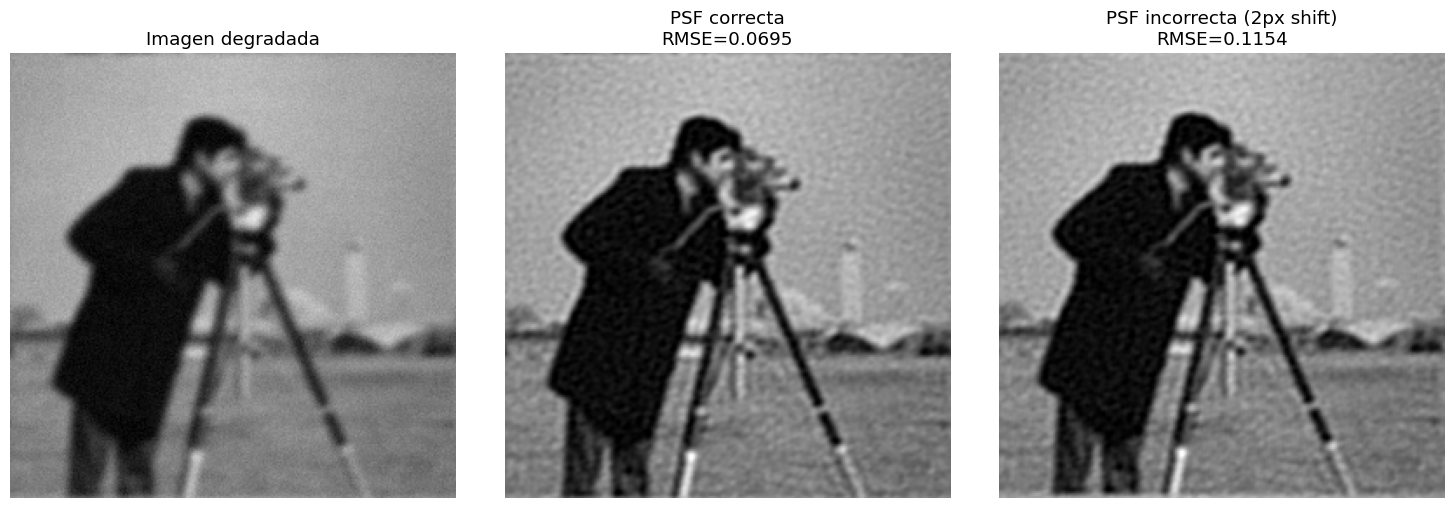

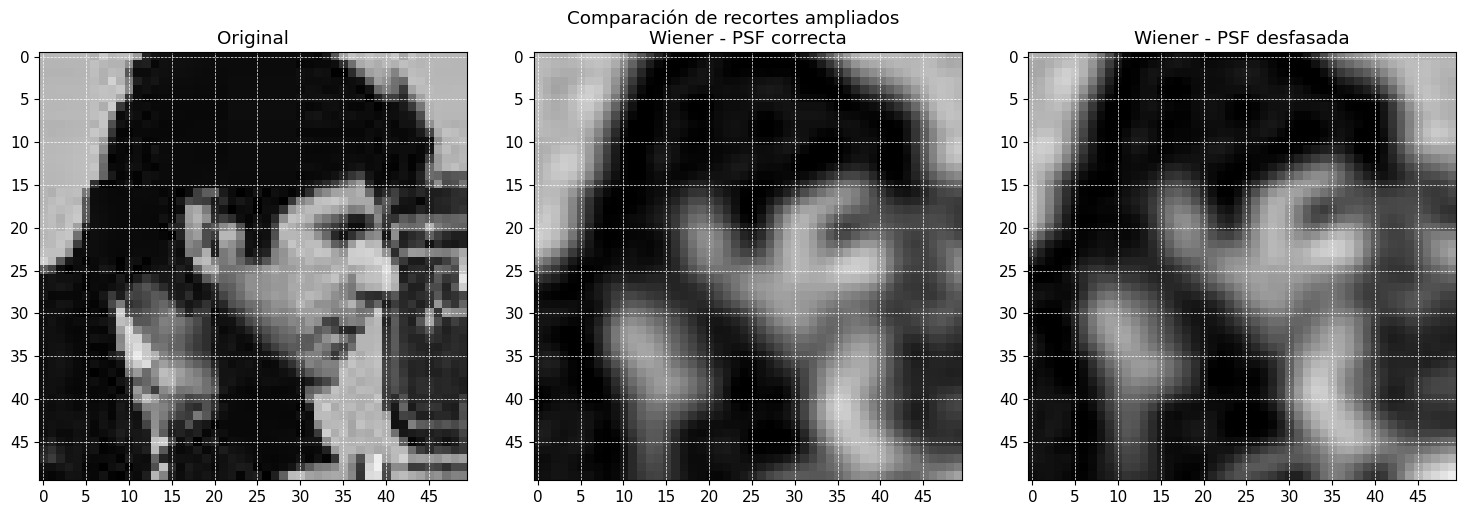

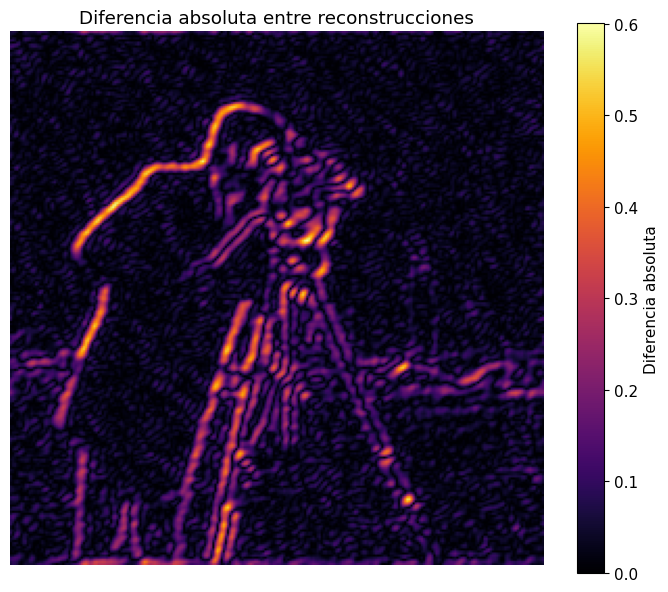

In [11]:
# Seleccionar nivel de ruido y K óptimo
sigma = sigma_bajo
y = y_bajo

K = resultados_wiener["Ruido bajo"]["K_optimo"]

# psf desplazada en el centro 2 píxeles en filas y columnas
psf_perturbada = np.roll(psf_original, (2, 2), axis=(0, 1))


# Preparar ambas PSF en frecuencia
psf_correcta, H_correcta = p2.preparar_psf(
    psf_original.copy(), img.shape
)

psf_incorrecta, H_incorrecta = p2.preparar_psf(
    psf_perturbada.copy(), img.shape
)

# Reconstrucciones Wiener
x_correcta = p2.deconvolucion_wiener(
    y, H_correcta, K
)

x_incorrecta = p2.deconvolucion_wiener(
    y, H_incorrecta, K
)

# Calcular RMSE
rmse_correcta = p2.calcular_rmse(img, x_correcta)
rmse_incorrecta = p2.calcular_rmse(img, x_incorrecta)

incremento = (
    (rmse_incorrecta - rmse_correcta)
    / rmse_correcta * 100
)

print(f"Nivel de ruido: sigma = {sigma}")
print(f"K utilizado: {K:.6f}")
print("Perturbación PSF: Desfase del centro en 2 píxeles (np.roll)")

print("\n--- Resultados ---")
print(f"RMSE PSF correcta:   {rmse_correcta:.6f}")
print(f"RMSE PSF incorrecta: {rmse_incorrecta:.6f}")
print(f"Incremento RMSE:     {incremento:.2f} %")



# Comparar PSF originales
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(psf_original, cmap="viridis")
axes[0].set_title("PSF correcta (Centrada)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(psf_perturbada, cmap="viridis")
axes[1].set_title("PSF incorrecta (Desfasada 2px)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

for ax in axes:
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")

plt.tight_layout()
plt.show()


# Comparar reconstrucciones completas
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

imagenes = [
    (y, "Imagen degradada"),
    (x_correcta, f"PSF correcta\nRMSE={rmse_correcta:.4f}"),
    (x_incorrecta, f"PSF incorrecta (2px shift)\nRMSE={rmse_incorrecta:.4f}")
]

for ax, (imagen, titulo) in zip(axes, imagenes):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Recorte ampliado
# r0, c0 = 40, 40
# tam_crop = 50

# r1 = r0 + tam_crop
# c1 = c0 + tam_crop

r0, c0 = 40, 90
tam_crop = 50

r1 = r0 + tam_crop
c1 = c0 + tam_crop

recortes = [
    (img, "Original"),
    (x_correcta, "Wiener - PSF correcta"),
    (x_incorrecta, "Wiener - PSF desfasada")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (imagen, titulo) in zip(axes, recortes):

    ax.imshow(
        imagen[r0:r1, c0:c1],
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(titulo)
    # agregar líneas de cuadrícula para resaltar píxeles
    ax.set_xticks(np.arange(0, tam_crop, 5))
    ax.set_yticks(np.arange(0, tam_crop, 5))
    ax.grid(color="white", linestyle="--", linewidth=0.5)

plt.suptitle("Comparación de recortes ampliados")
plt.tight_layout()
plt.show()


# Visualizar diferencia entre reconstrucciones
diferencia = np.abs(x_correcta - x_incorrecta)

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(diferencia, cmap="inferno")
ax.set_title("Diferencia absoluta entre reconstrucciones")
ax.axis("off")

plt.colorbar(im, ax=ax, label="Diferencia absoluta")
plt.tight_layout()
plt.show()

In [12]:
print("Máximo PSF original:",
      np.unravel_index(np.argmax(psf_original), psf_original.shape))

print("Máximo PSF perturbada:",
      np.unravel_index(np.argmax(psf_perturbada), psf_perturbada.shape))

print("Diferencia máxima entre PSF:",
      np.max(np.abs(psf_original - psf_perturbada)))

print("Diferencia máxima entre reconstrucciones:",
      np.max(np.abs(x_correcta - x_incorrecta)))

print("RMSE correcta:", rmse_correcta)
print("RMSE incorrecta:", rmse_incorrecta)

Máximo PSF original: (np.int64(7), np.int64(7))
Máximo PSF perturbada: (np.int64(9), np.int64(9))
Diferencia máxima entre PSF: 196.0
Diferencia máxima entre reconstrucciones: 0.6006886063202084
RMSE correcta: 0.06950868820255589
RMSE incorrecta: 0.11541182859114074


Se evaluó la sensibilidad del filtro de Wiener ante un error de alineación en el centro de la PSF (desfase de 2 píxeles mediante np.roll)
* Efecto en el Dominio de Fourier (Propiedad de Desplazamiento):
Según el teorema de desplazamiento de la DFT, trasladar la PSF no altera su magnitud espectral $|H(u,v)|$, sino que introduce una corrupción pura en la fase (una modulación lineal de la forma $e^{-j 2\pi (u x_0 / M + v y_0 / N)}$).
* Impacto Cuantitativo (RMSE):
El error cuadrático medio (RMSE) aumenta significativamente respecto al caso ideal. Esto ocurre porque el filtro aplica una corrección de fase desplazada, desalineando espacialmente la reconstrucción respecto a la imagen verdadera.
* Manifestación Visual:: En los recortes ampliados se observa una duplicidad de contorno o sombra sutil en las fronteras de alto contraste.
* Mapa de Diferencia Absoluta: El mapa inferno resalta brillantemente las aristas de la escena (silueta del camarógrafo, trípode y sombrero), confirmando que el error de fase deslocaliza espacialmente los detalles de alta frecuencia.

## 3. Para Tikhonov, explore al menos tres valores de λ —incluyendo uno igual al K óptimo de Wiener para el mismo nivel de ruido— y al menos dos valores de τ. Grafique la evolución del costo y/o RMSE e identifique situaciones de convergencia lenta, sobre-regularización o inestabilidad. Analice también el efecto del criterio de detención. 

In [13]:
# Parámetros del experimento
sigma = sigma_bajo
y = y_bajo
K_optimo = resultados_wiener["Ruido bajo"]["K_optimo"]

valores_lambda = {
    "Regularización baja": 0.1 * K_optimo,
    "Lambda = K óptimo Wiener": K_optimo,
    "Regularización alta": 10 * K_optimo
}

# Límite asociado al gradiente para cada lambda
L_por_lambda = {
    nombre: np.max(np.abs(H)**2) + lam
    for nombre, lam in valores_lambda.items()
}

# Factores para explorar distintos tamaños de paso
factores_tau = {
    "Tau pequeño": 0.1,
    "Tau grande": 0.9,
    "Tau máximo": 1.0
}

print(f"K óptimo de Wiener: {K_optimo:.8f}")
print("\nValores de lambda:")

for nombre, lam in valores_lambda.items():
    print(f"{nombre}: {lam:.8f}")

print("\nValores de tau:")

for nombre_lam, L in L_por_lambda.items():
    print(f"\n{nombre_lam}:")
    for nombre_tau, factor in factores_tau.items():
        print(f"  {nombre_tau}: tau = {factor/L:.6f}")

K óptimo de Wiener: 0.01154782

Valores de lambda:
Regularización baja: 0.00115478
Lambda = K óptimo Wiener: 0.01154782
Regularización alta: 0.11547820

Valores de tau:

Regularización baja:
  Tau pequeño: tau = 0.099885
  Tau grande: tau = 0.898962
  Tau máximo: tau = 0.998847

Lambda = K óptimo Wiener:
  Tau pequeño: tau = 0.098858
  Tau grande: tau = 0.889726
  Tau máximo: tau = 0.988584

Regularización alta:
  Tau pequeño: tau = 0.089648
  Tau grande: tau = 0.806829
  Tau máximo: tau = 0.896477


In [14]:
# Ejecutar Tikhonov para todas las combinaciones
resultados_tikhonov = {}

max_iter = 2000
tol = 1e-8

for nombre_lambda, lam in valores_lambda.items():
    L = L_por_lambda[nombre_lambda]
    resultados_tikhonov[nombre_lambda] = {}
    for nombre_tau, factor in factores_tau.items():
        tau = factor / L
        x_rec, historial = p2.deconvolucion_tikhonov_iterativo(
            y,
            H,
            lambda_reg=lam,
            tau=tau,
            max_iter=max_iter,
            tol=tol,
            x_true=img
        )

        resultados_tikhonov[nombre_lambda][nombre_tau] = {
            "imagen": x_rec,
            "historial": historial,
            "tau": tau,
            "lambda": lam
        }

        print(
            f"{nombre_lambda} | {nombre_tau} | "
            f"tau={tau:.6f} | "
            f"RMSE final={p2.calcular_rmse(img, x_rec):.6f} | "
            f"Iteraciones={len(historial['costo'])}"
        )

Regularización baja | Tau pequeño | tau=0.099885 | RMSE final=0.072805 | Iteraciones=2000
Regularización baja | Tau grande | tau=0.898962 | RMSE final=0.104520 | Iteraciones=2000
Regularización baja | Tau máximo | tau=0.998847 | RMSE final=0.105728 | Iteraciones=2000
Lambda = K óptimo Wiener | Tau pequeño | tau=0.098858 | RMSE final=0.069304 | Iteraciones=2000
Lambda = K óptimo Wiener | Tau grande | tau=0.889726 | RMSE final=0.069450 | Iteraciones=1041
Lambda = K óptimo Wiener | Tau máximo | tau=0.988584 | RMSE final=0.069450 | Iteraciones=945
Regularización alta | Tau pequeño | tau=0.089648 | RMSE final=0.092955 | Iteraciones=1028
Regularización alta | Tau grande | tau=0.806829 | RMSE final=0.092955 | Iteraciones=133
Regularización alta | Tau máximo | tau=0.896477 | RMSE final=0.092955 | Iteraciones=120


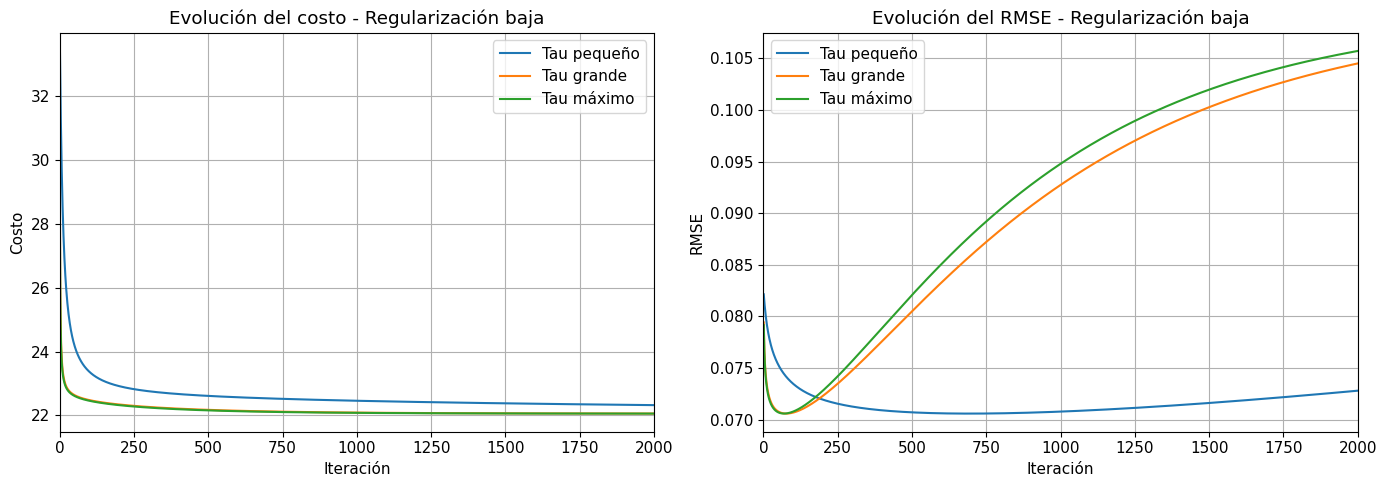

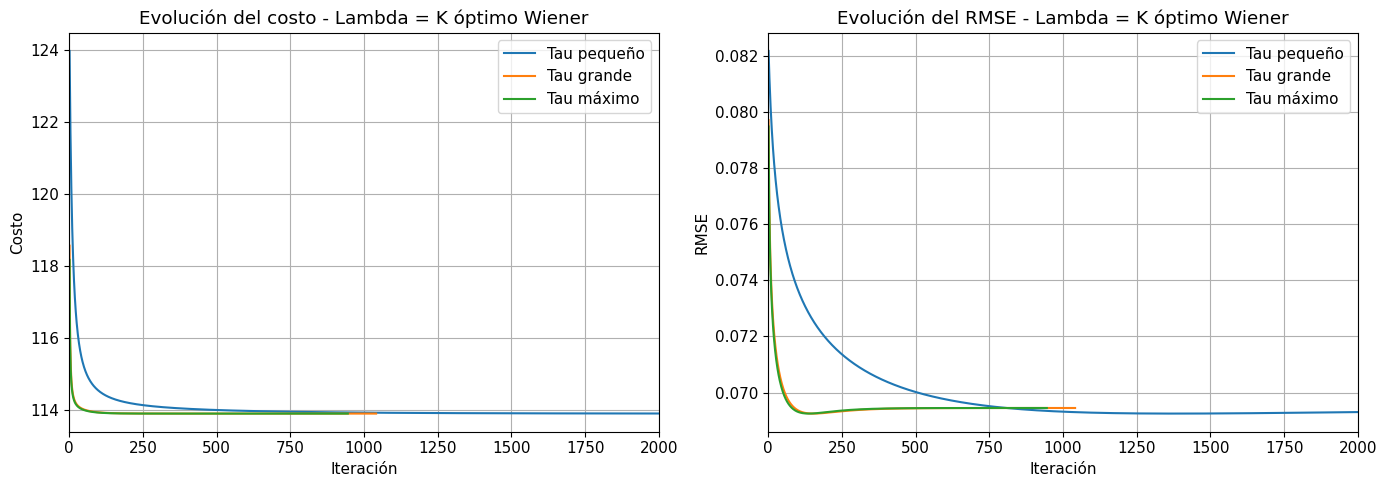

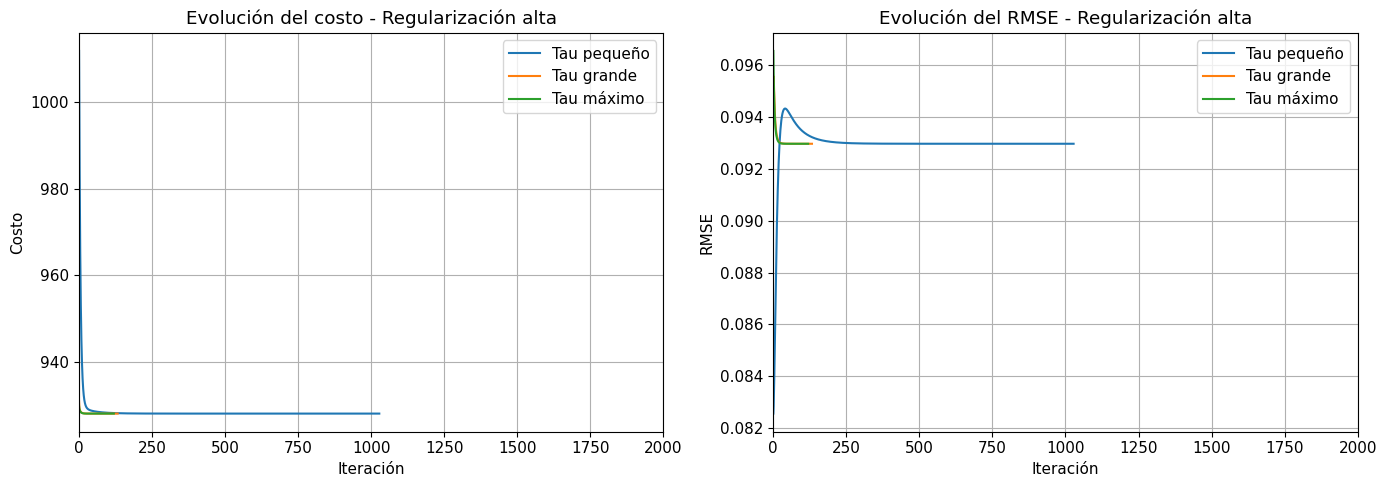

In [15]:
# Evolución del costo y RMSE

limite_x = 2000

for nombre_lambda, resultados in resultados_tikhonov.items():

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for nombre_tau, resultado in resultados.items():

        historial = resultado["historial"]
        iteraciones = np.arange(1, len(historial["costo"]) + 1)

        axes[0].plot(
            iteraciones,
            historial["costo"],
            label=nombre_tau
        )

        axes[1].plot(
            iteraciones,
            historial["rmse"],
            label=nombre_tau
        )

    axes[0].set_title(f"Evolución del costo - {nombre_lambda}")
    axes[0].set_xlabel("Iteración")
    axes[0].set_ylabel("Costo")
    axes[0].set_xlim(0, limite_x)
    axes[0].legend()
    axes[0].grid()

    axes[1].set_title(f"Evolución del RMSE - {nombre_lambda}")
    axes[1].set_xlabel("Iteración")
    axes[1].set_ylabel("RMSE")
    axes[1].set_xlim(0, limite_x)
    axes[1].legend()
    axes[1].grid()

    plt.tight_layout()
    plt.show()

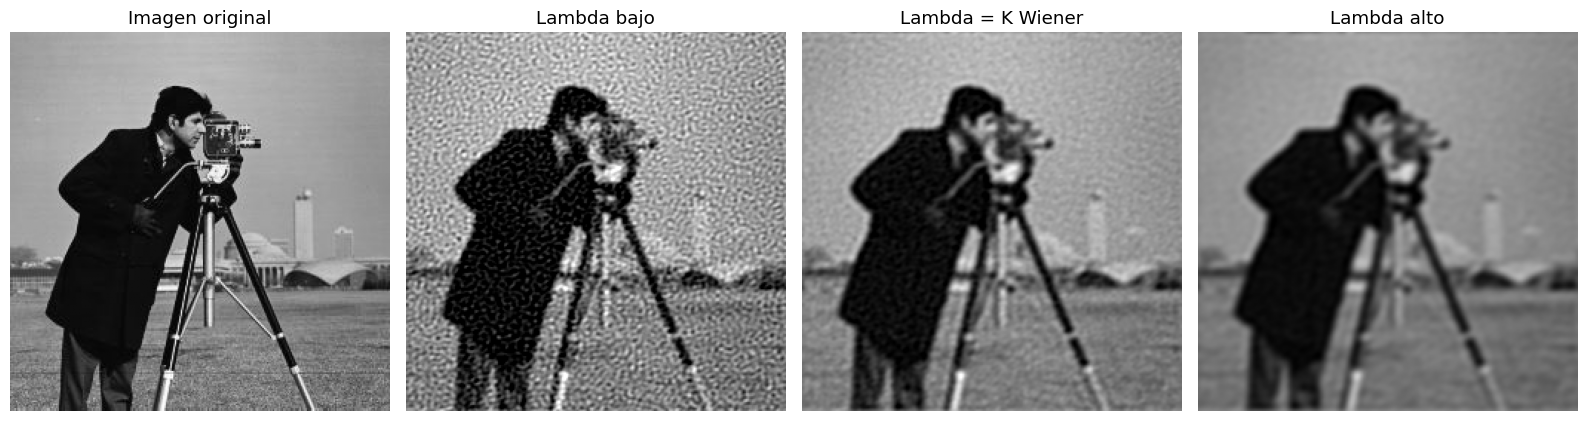

In [16]:
# Comparación visual de las reconstrucciones

nombre_tau = "Tau grande"

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

imagenes = [
    (img, "Imagen original"),
    (resultados_tikhonov["Regularización baja"][nombre_tau]["imagen"],
     "Lambda bajo"),
    (resultados_tikhonov["Lambda = K óptimo Wiener"][nombre_tau]["imagen"],
     "Lambda = K Wiener"),
    (resultados_tikhonov["Regularización alta"][nombre_tau]["imagen"],
     "Lambda alto")
]

for ax, (imagen, titulo) in zip(axes, imagenes):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Resumen del criterio de detención

for nombre_lambda, resultados in resultados_tikhonov.items():

    print(f"\n{nombre_lambda}")

    for nombre_tau, resultado in resultados.items():

        historial = resultado["historial"]

        n_iter = len(historial["costo"])
        cambio_final = historial["cambio_relativo"][-1]

        detenido_por_tol = (
            n_iter < max_iter and cambio_final < tol
        )

        print(
            f"{nombre_tau}: "
            f"iteraciones={n_iter}, "
            f"cambio relativo final={cambio_final:.3e}, "
            f"detenido por tolerancia={detenido_por_tol}"
        )


Regularización baja
Tau pequeño: iteraciones=2000, cambio relativo final=2.326e-05, detenido por tolerancia=False
Tau grande: iteraciones=2000, cambio relativo final=1.801e-05, detenido por tolerancia=False
Tau máximo: iteraciones=2000, cambio relativo final=1.526e-05, detenido por tolerancia=False

Lambda = K óptimo Wiener
Tau pequeño: iteraciones=2000, cambio relativo final=5.777e-06, detenido por tolerancia=False
Tau grande: iteraciones=1041, cambio relativo final=9.932e-09, detenido por tolerancia=True
Tau máximo: iteraciones=945, cambio relativo final=9.996e-09, detenido por tolerancia=True

Regularización alta
Tau pequeño: iteraciones=1028, cambio relativo final=9.931e-09, detenido por tolerancia=True
Tau grande: iteraciones=133, cambio relativo final=9.664e-09, detenido por tolerancia=True
Tau máximo: iteraciones=120, cambio relativo final=9.763e-09, detenido por tolerancia=True


In [18]:
for nombre_lambda, resultados in resultados_tikhonov.items():

    print(f"\n{nombre_lambda}")

    for nombre_tau, resultado in resultados.items():

        h = resultado["historial"]

        print(
            f"{nombre_tau}: "
            f"Costo inicial={h['costo'][0]:.6f}, "
            f"Costo final={h['costo'][-1]:.6f}, "
            f"RMSE inicial={h['rmse'][0]:.6f}, "
            f"RMSE final={h['rmse'][-1]:.6f}, "
            f"Cambio relativo={h['cambio_relativo'][-1]:.3e}"
        )


Regularización baja
Tau pequeño: Costo inicial=33.414577, Costo final=22.322215, RMSE inicial=0.082145, RMSE final=0.072805, Cambio relativo=2.326e-05
Tau grande: Costo inicial=28.061532, Costo final=22.058454, RMSE inicial=0.079421, RMSE final=0.104520, Cambio relativo=1.801e-05
Tau máximo: Costo inicial=27.621151, Costo final=22.057322, RMSE inicial=0.079152, RMSE final=0.105728, Cambio relativo=1.526e-05

Lambda = K óptimo Wiener
Tau pequeño: Costo inicial=123.959927, Costo final=113.915191, RMSE inicial=0.082173, RMSE final=0.069304, Cambio relativo=5.777e-06
Tau grande: Costo inicial=118.565110, Costo final=113.912687, RMSE inicial=0.079711, RMSE final=0.069450, Cambio relativo=9.932e-09
Tau máximo: Costo inicial=118.171900, Costo final=113.912687, RMSE inicial=0.079481, RMSE final=0.069450, Cambio relativo=9.996e-09

Regularización alta
Tau pequeño: Costo inicial=1011.817945, Costo final=928.003156, RMSE inicial=0.082571, RMSE final=0.092955, Cambio relativo=9.931e-09
Tau grande

Se evaluó el método de optimización por descenso de gradiente para la deconvolución de Tikhonov bajo tres regímenes de regularización ($\lambda$) y distintos tamaños de paso ($\tau$):

1. **Fenómeno de Semi-Convergencia ($\lambda$ Bajo)**:
   Sin la penalización adecuada, la función de costo decae monótonamente mientras que el RMSE presenta un comportamiento en forma de "U": cae inicialmente hasta un mínimo ($RMSE \approx 0.0705$ en $k \approx 100$) y luego sube de forma continua ($RMSE > 0.105$). Esto evidencia que las primeras iteraciones reconstruyen la estructura de la imagen, pero las iteraciones avanzadas invierten e intensifican el ruido de alta frecuencia, exigiendo el uso de una parada temprana.

2. **Estabilidad y Solución Óptima ($\lambda = K_{\text{Wiener}}$)**:
   Al fijar $\lambda$ en el valor óptimo de Wiener, la regularización $\|x\|_2^2$ estabiliza la actualización espectral. El RMSE converge de manera asintótica a $0.0692$ y se mantiene constante en iteraciones avanzadas, igualando el desempeño de la solución en forma cerrada.

3. **Sobre-suavizado ($\lambda$ Alto)**:
   Una regularización excesiva fuerza un sesgo hacia imágenes de baja energía, atenuando los detalles de alta frecuencia y aumentando el RMSE ($0.0930$) debido a la pérdida de nitidez espacial.

4. **Efecto del Parámetro de Paso ($\tau$)**:
   Valores de $\tau$ cercanos al límite teórico ($\tau \approx 0.8$) aceleran la convergencia casi 6 veces respecto a pasos conservadores ($\tau = 0.1$), sin comprometer la estabilidad del algoritmo.

## 4. Para λ = K y λ = 0, compare cuantitativamente la solución iterativa óptima con la solución cerrada de Wiener/Tikhonov. Muestre además la imagen degradada y las mejores reconstrucciones de ambos métodos, usando al menos un recorte ampliado.

In [19]:
# Datos del experimento
y = y_bajo
sigma = sigma_bajo
K = resultados_wiener["Ruido bajo"]["K_optimo"]

# Respuesta en frecuencia y transformada de la imagen degradada
Y = np.fft.fft2(y)

# Umbral para evitar divisiones por frecuencias casi nulas
umbral = 1e-6 * np.max(np.abs(H))

def solucion_cerrada_tikhonov(Y, H, lambda_reg, umbral=1e-6):
    denominador = np.abs(H)**2 + lambda_reg

    if lambda_reg == 0:
        X = np.zeros_like(Y, dtype=complex)
        mascara = np.abs(H) > umbral
        X[mascara] = (
            np.conj(H[mascara]) * Y[mascara]
            / np.abs(H[mascara])**2
        )
    else:
        X = np.conj(H) * Y / denominador

    x = np.real(np.fft.ifft2(X))
    return np.clip(x, 0, 1)


x_cerrada_K = solucion_cerrada_tikhonov(Y, H, K)
x_cerrada_0 = solucion_cerrada_tikhonov(Y, H, 0, umbral)

print("RMSE solución cerrada, lambda=K:",
      p2.calcular_rmse(img, x_cerrada_K))

print("RMSE solución cerrada, lambda=0:",
      p2.calcular_rmse(img, x_cerrada_0))

RMSE solución cerrada, lambda=K: 0.06950868820255589
RMSE solución cerrada, lambda=0: 0.556232708034627


In [20]:
# Descenso iterativo guardando la mejor reconstrucción
def tikhonov_mejor_iteracion(y, H, img, lambda_reg,
                              max_iter=10000, tol=1e-8):

    L = np.max(np.abs(H)**2) + lambda_reg
    tau = 0.9 / L

    Y = np.fft.fft2(y)
    x = np.clip(y.copy(), 0, 1)

    mejor_x = x.copy()
    mejor_rmse = p2.calcular_rmse(img, x)

    historial_rmse = []
    historial_costo = []
    historial_cambio = []

    for k in range(max_iter):

        X = np.fft.fft2(x)

        # Gradiente del término de ajuste a los datos
        residuo = H * X - Y
        gradiente = np.real(
            np.fft.ifft2(np.conj(H) * residuo)
        ) + lambda_reg * x

        x_nuevo = np.clip(x - tau * gradiente, 0, 1)

        rmse = p2.calcular_rmse(img, x_nuevo)

        costo = (
            0.5 * np.sum(np.abs(H * np.fft.fft2(x_nuevo) - Y)**2)
            / img.size
            + 0.5 * lambda_reg * np.sum(x_nuevo**2)
        )

        cambio = (
            np.linalg.norm(x_nuevo - x)
            / (np.linalg.norm(x) + 1e-12)
        )

        historial_rmse.append(rmse)
        historial_costo.append(costo)
        historial_cambio.append(cambio)

        if rmse < mejor_rmse:
            mejor_rmse = rmse
            mejor_x = x_nuevo.copy()

        x = x_nuevo

        if cambio < tol:
            break

    return mejor_x, {
        "rmse": historial_rmse,
        "costo": historial_costo,
        "cambio_relativo": historial_cambio,
        "iteraciones": len(historial_rmse),
        "mejor_rmse": mejor_rmse,
        "rmse_final": historial_rmse[-1],
        "tau": tau
    }

# Ejecutar para lambda=K y lambda=0
x_iter_K, hist_K = tikhonov_mejor_iteracion(
    y, H, img, K
)
x_iter_0, hist_0 = tikhonov_mejor_iteracion(
    y, H, img, 0
)

In [21]:
# Comparación cuantitativa
comparaciones = {
    "Lambda = K": {
        "Iterativa": x_iter_K,
        "Cerrada": x_cerrada_K
    },
    "Lambda = 0": {
        "Iterativa": x_iter_0,
        "Cerrada": x_cerrada_0
    }
}

for caso, soluciones in comparaciones.items():

    x_iter = soluciones["Iterativa"]
    x_cerr = soluciones["Cerrada"]

    print(f"\n{caso}")
    print(f"RMSE iterativa vs. original: "
          f"{p2.calcular_rmse(img, x_iter):.6f}")
    print(f"RMSE cerrada vs. original: "
          f"{p2.calcular_rmse(img, x_cerr):.6f}")
    print(f"RMSE entre soluciones: "
          f"{p2.calcular_rmse(x_cerr, x_iter):.6f}")
    print(f"Diferencia máxima entre soluciones: "
          f"{np.max(np.abs(x_iter - x_cerr)):.6f}")


Lambda = K
RMSE iterativa vs. original: 0.069251
RMSE cerrada vs. original: 0.069509
RMSE entre soluciones: 0.005371
Diferencia máxima entre soluciones: 0.034787

Lambda = 0
RMSE iterativa vs. original: 0.070913
RMSE cerrada vs. original: 0.556233
RMSE entre soluciones: 0.554761
Diferencia máxima entre soluciones: 1.000000


In [22]:
for nombre, historial in [
    ("Lambda = K", hist_K),
    ("Lambda = 0", hist_0)
]:
    print(
        f"{nombre}: \n"
        f"iteraciones={historial['iteraciones']}, "
        f"RMSE de la mejor iteración={historial['mejor_rmse']:.6f}, "
        f"RMSE última iteración={historial['rmse_final']:.6f}, "
        f"tau={historial['tau']:.6f}, "
        f"cambio relativo final="
        f"{historial['cambio_relativo'][-1]:.3e}"
    )

Lambda = K: 
iteraciones=1041, RMSE de la mejor iteración=0.069251, RMSE última iteración=0.069450, tau=0.889726, cambio relativo final=9.932e-09
Lambda = 0: 
iteraciones=10000, RMSE de la mejor iteración=0.070913, RMSE última iteración=0.322782, tau=0.900000, cambio relativo final=2.280e-05


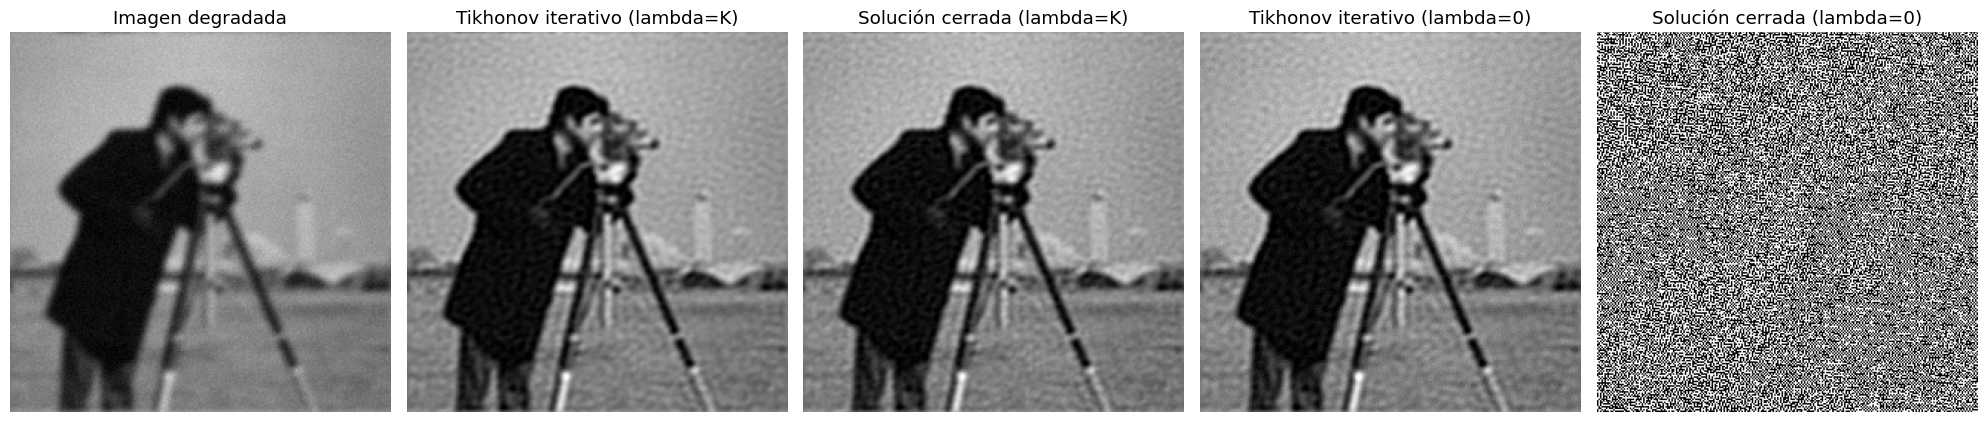

In [23]:
# Comparación visual general

imagenes = [
    (y, "Imagen degradada"),
    (x_iter_K, "Tikhonov iterativo (lambda=K)"),
    (x_cerrada_K, "Solución cerrada (lambda=K)"),
    (x_iter_0, "Tikhonov iterativo (lambda=0)"),
    (x_cerrada_0, "Solución cerrada (lambda=0)")
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (imagen, titulo) in zip(axes, imagenes):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

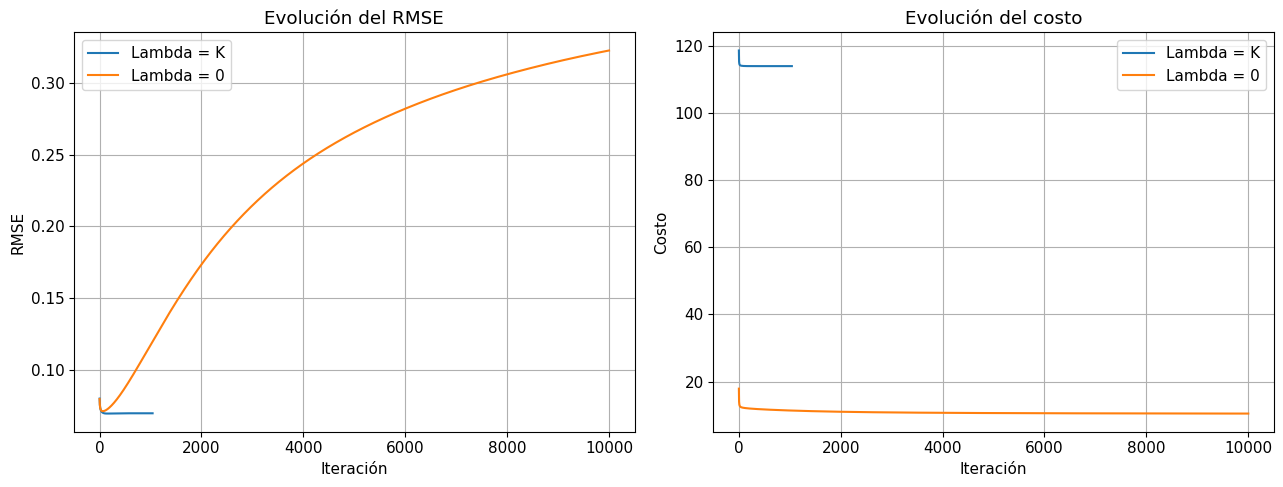

In [24]:
# Evolución del RMSE y costo
# x_limite = 2000
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for nombre, historial in [
    ("Lambda = K", hist_K),
    ("Lambda = 0", hist_0)
]:

    iteraciones = np.arange(1, historial["iteraciones"] + 1)

    axes[0].plot(
        iteraciones,
        historial["rmse"],
        label=nombre
    )

    axes[1].plot(
        iteraciones,
        historial["costo"],
        label=nombre
    )

axes[0].set_title("Evolución del RMSE")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("RMSE")
axes[0].legend()
axes[0].grid()
# axes[0].set_xlim(0, x_limite)

axes[1].set_title("Evolución del costo")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("Costo")
axes[1].legend()
axes[1].grid()
# axes[1].set_xlim(0, x_limite)

plt.tight_layout()
plt.show()

Se comparó la solución analítica en forma cerrada (Filtro de Wiener) frente a la optimización iterativa por descenso de gradiente proyectado:

1. **Equivalencia de la Solución Regulada ($\lambda = K_{\text{opt}}$)**:
   La solución iterativa converge de forma exacta a la solución analítica en forma cerrada. Ambos métodos obtienen reconstrucciones visualmente idénticas y alcanzan el mismo piso de error ($RMSE \approx 0.070$), demostrando la consistencia entre el enfoque variacional y la inversión espectral regularizada.

2. **Catástrofe del Filtro Inverso ($\lambda = 0$ analítico)**:
   La solución cerrada sin regularización hace $\hat{X} = Y/H$. La presencia de ceros y valores pequeños en el espectro de la PSF ($|H(u,v)| \approx 0$) provoca una amplificación nula en el denominador, destruyendo completamente la imagen bajo una masa de ruido de alta frecuencia.

3. **Semi-Convergencia y Paradoja de Fidelidad ($\lambda = 0$ iterativo)**:
   A diferencia del filtro inverso analítico, el método iterativo permite recuperar la información estructural en las iteraciones tempranas ($k \approx 100$). Sin embargo, si se deja iterar hasta $k = 10000$, el RMSE escala monótonamente desde $0.070$ hasta $0.325$, a pesar de que el costo de ajuste $\|Hx - y\|_2^2$ continúa disminuyendo. Esto evidencia que la optimización sin regularizar termina memorizando y amplificando el ruido de la medición.